# Detector-map residual plots

`pfs.drp.qa.plotting.dmResiduals.plotDetectorResiduals` draws one detector image's line
residuals from the stored `dmLineResidualData`, replacing the retired `dmResiduals` task's
1D and 2D views so the pipeline renders no detector-map plot. It is stack-free: a
DataFrame in, a `matplotlib.figure.Figure` out.

The data here is **synthetic**, so this notebook commits without a proprietary frame; a
real detector reads the same columns from a Butler collection, where the km/s values and
the lamp species are the stored ones.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

from pfs.drp.qa.plotting.dmResiduals import plotDetectorResiduals

W, H = 4096, 4176


def makeDetectorResiduals(seed=0, kms=True):
    """A synthetic one-detector ``dmLineResidualData`` frame: traces (x only) and lamp
    lines of three species, a coherent drift against calib, centred scatter against the
    visit's own detectorMap, and a few outliers."""
    rng = np.random.default_rng(seed)
    fiberIds = np.linspace(2, 650, 80).astype(int)
    fiberX = np.interp(fiberIds, (fiberIds.min(), fiberIds.max()), (120, W - 120))
    rows = []
    for fid, x0 in zip(fiberIds, fiberX):
        for y in np.sort(rng.uniform(150, H - 150, 24)):
            rows.append(("Trace", fid, np.nan, x0 + rng.normal(0, 3), y))
    for name, wls in {"NeI": (955, 1010, 1120), "HgI": (980, 1040, 1130), "CdI": (970, 1050)}.items():
        for fid, x0 in zip(fiberIds[::2], fiberX[::2]):
            for wl in wls:
                y = np.interp(wl, (950, 1250), (150, H - 150)) + rng.normal(0, 10)
                rows.append((name, fid, wl, x0 + rng.normal(0, 5), y))
    df = pd.DataFrame(rows, columns=["description", "fiberId", "wavelength", "x", "y"])
    n = len(df)
    df["visit"], df["arm"], df["spectrograph"] = 123456, "n", 3
    df["xErr"] = df["yErr"] = 0.02
    df["statusType"] = rng.choice(["USED", "RESERVED"], n, p=[0.8, 0.2])
    xn, yn = (df["x"] - W / 2) / (W / 2), (df["y"] - H / 2) / (H / 2)
    df["dxCalib"] = 0.06 + 0.05 * xn + rng.normal(0, 0.02, n)   # coherent drift
    df["dyCalib"] = -0.04 + 0.03 * yn + rng.normal(0, 0.02, n)
    df["dxVisit"] = rng.normal(0, 0.03, n)
    df["dyVisit"] = rng.normal(0, 0.03, n)
    outliers = rng.choice(n, 10, replace=False)
    df.loc[outliers, ["dxVisit", "dyVisit"]] += rng.normal(0, 0.2, (10, 2))
    df.loc[df["description"] == "Trace", ["dyCalib", "dyVisit"]] = np.nan
    if kms:
        df["dyKmsCalib"] = df["dyCalib"] * 25.0
        df["dyKmsVisit"] = df["dyVisit"] * 25.0
    return df


data = makeDetectorResiduals()
data.head()


,description,fiberId,wavelength,x,y,visit,arm,spectrograph,xErr,yErr,statusType,dxCalib,dyCalib,dxVisit,dyVisit,dyKmsCalib,dyKmsVisit
0,Trace,2,NaN,122.710411,160.614427,123456,n,3,0.02,0.02,USED,0.034146,NaN,0.063683,NaN,NaN,NaN
1,Trace,2,NaN,120.282037,214.061115,123456,n,3,0.02,0.02,USED,0.000686,NaN,0.022148,NaN,NaN,NaN
2,Trace,2,NaN,117.769502,259.767045,123456,n,3,0.02,0.02,USED,0.021478,NaN,-0.029049,NaN,NaN,NaN
3,Trace,2,NaN,117.234824,280.177690,123456,n,3,0.02,0.02,RESERVED,-0.000013,NaN,0.017962,NaN,NaN,NaN
4,Trace,2,NaN,118.626823,308.813379,123456,n,3,0.02,0.02,RESERVED,-0.003765,NaN,-0.030072,NaN,NaN,NaN


## The figure

Two rows — **Δx** (spatial: trace centroids and line x) and **Δy** (wavelength: lamp and
sky lines) — by three columns:

1. **calib-drift face map** — the median residual against the calibration detectorMap,
   binned over the detector face (drift since the calib was built);
2. **visit-scatter face map** — the same against the visit's own adjusted detectorMap (the
   reserved-line scatter the gate judges);
3. **trend** — the reserved lines' visit residual coloured by species, each reference's
   per-fiber (Δx) or per-wavelength (Δy) median over them, the gate's warn/fail bands
   (`limits`), and a reserved median / robust-RMS / outlier box.

A coherent drift shows as a uniform tint in the calib map; random scatter shows in the
visit map. Pass `limits` to draw the gate bands.


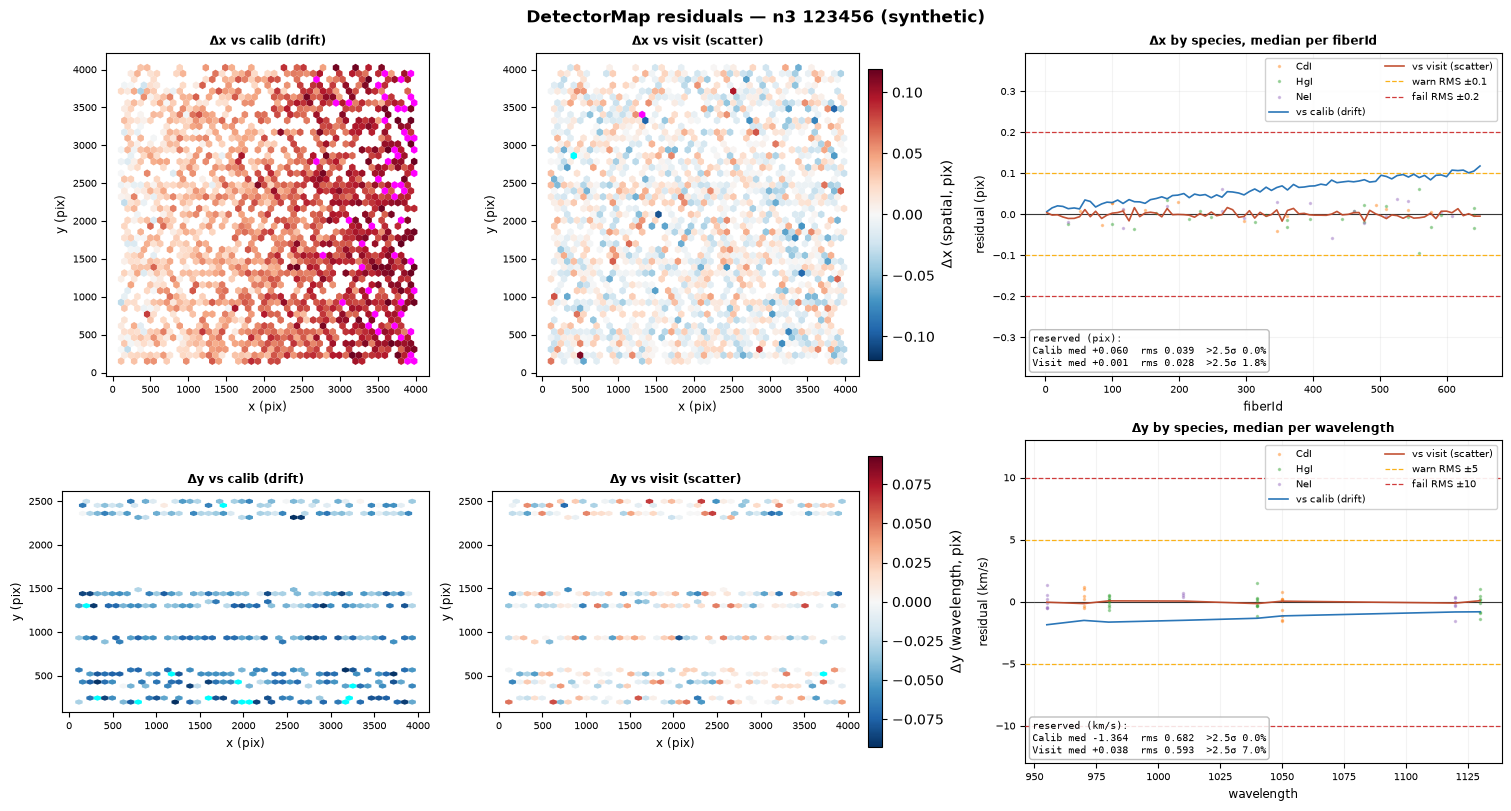

In [2]:
limits = {"dx": (0.10, 0.20), "dy": (5.0, 10.0)}  # gate warn, fail RMS (pix; km/s)
fig = plotDetectorResiduals(data, title="n3 123456 (synthetic)", limits=limits)
fig


### Notes

- **km/s or pixels.** The Δy trend is in km/s when the collection stored `dyKmsCalib` /
  `dyKmsVisit` (the judged quantity); an older collection, or a trace-only quartz frame,
  falls back to pixels.
- **Gate bands.** Without `limits` no band is drawn; the caller passes the gate's warn/fail
  RMS from the metric registry.
- **Outliers.** The stats box counts reserved lines more than 2.5 robust RMS from the
  median, so a single wild line is counted but clipped from the y-scale rather than
  flattening it.
- **Where it is drawn.** From any Butler collection's `dmLineResidualData` after the fact
  (a notebook, or the QA dashboard's per-visit page); the pipeline renders nothing.
